In [1]:
import glob
import ast
import json
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid


In [2]:
target = "ClosePrice"

def n_months(path):
    return int(re.search(r"train_(\d+)m", str(path)).group(1))

def metrics(y_true, y_pred):
    ape = np.abs(y_pred - y_true) / y_true
    mse = mean_squared_error(y_true, y_pred)

    return {
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": ape.mean() * 100,
        "MdAPE_%": np.median(ape) * 100,
        "MAE_$": mean_absolute_error(y_true, y_pred),
        "MSE_$2": mse,
        "RMSE_$": np.sqrt(mse),
    }

# fe_outputs/train_6m ... train_30m, each with features_train/val/test.csv
split_dirs = sorted(
    (d for d in glob.glob("fe_outputs/train_*m") if 6 <= n_months(d) <= 30),
    key=n_months
)
print([n_months(d) for d in split_dirs])

# columns that must never be model features. Any column with "date" in its
# name is also excluded.
EXCLUDE_COLS = ["CloseDate"]
_warned = set()

def load_split(folder):
    """Load train/val/test for one window and return numeric features + target."""
    train = pd.read_csv(f"{folder}/features_train.csv")
    val = pd.read_csv(f"{folder}/features_val.csv")
    test = pd.read_csv(f"{folder}/features_test.csv")

    # never use close date (or anything derived from it) as a feature, plus
    # any non-numeric column (dates, IDs, text); chosen from train
    banned = [c for c in train.columns
              if c in EXCLUDE_COLS or "date" in c.lower()]
    feats = (train.drop(columns=[target] + banned)
                  .select_dtypes(include="number").columns)
    dropped = [c for c in train.columns if c != target and c not in feats]
    if dropped and tuple(dropped) not in _warned:
        _warned.add(tuple(dropped))
        print(f"Excluded from features: {dropped}")

    X_tr, X_val, X_te = (
        df[feats].replace([np.inf, -np.inf], np.nan) for df in (train, val, test)
    )

    # fill any missing values with train-set medians (same fill for all splits)
    med = X_tr.median()
    X_tr, X_val, X_te = X_tr.fillna(med), X_val.fillna(med), X_te.fillna(med)

    return X_tr, train[target], X_val, val[target], X_te, test[target]


[6, 9, 12, 15, 18, 21, 24, 27]


In [3]:
# "auto": reuse saved best parameters; tune only if they haven't been saved yet.
# "tune": force a new hyperparameter search for every model/window.
# "best_only": train ONLY with saved best parameters (error if any are missing).
TUNING_MODE = "best_only"

BEST_PARAMS_FILE = "tree_forest_best_params.json"
RESULTS_FILE = "tree_forest_results.csv"
TUNING_RESULTS_FILE = "tree_forest_tuning_results.csv"

rows = []
tuning_rows = []
best_models = {}  # keep each window's best-parameter models for later plots

# Keep your original search grid, used only when tuning is needed.
param_grids = {
    "DecisionTree": {
        "max_depth": [5, 10, 20, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 3, 5],
    },
    "RandomForest": {
        "n_estimators": [100, 200],
        "max_depth": [10, 20, None],
        "max_features": ["sqrt", 0.5, 0.8],
        "min_samples_leaf": [1, 3, 5],
    },
}

if TUNING_MODE not in {"auto", "tune", "best_only"}:
    raise ValueError("TUNING_MODE must be 'auto', 'tune', or 'best_only'")

# Read best parameters from the new JSON file OR your original results CSV.
# This makes results from previous notebook runs usable without tuning again.
saved_params = {}
if TUNING_MODE != "tune":
    if Path(RESULTS_FILE).exists():
        old_results = pd.read_csv(RESULTS_FILE)
        if {"model", "n_train_months", "best_params"}.issubset(old_results.columns):
            for _, row in old_results.dropna(subset=["best_params"]).iterrows():
                key = f"{int(row['n_train_months'])}m_{row['model']}"
                saved_params[key] = ast.literal_eval(row["best_params"])
    if Path(BEST_PARAMS_FILE).exists():
        saved_params.update(json.loads(Path(BEST_PARAMS_FILE).read_text()))

for folder in split_dirs:

    months = n_months(folder)

    X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)

    models = {
        "DecisionTree": DecisionTreeRegressor(
            max_depth=5,
            random_state=42
        ),
        "RandomForest": RandomForestRegressor(
            n_estimators=50,
            max_features=0.5,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    }

    best_models[months] = {}

    for name, model in models.items():
        key = f"{months}m_{name}"
        do_tune = TUNING_MODE == "tune" or key not in saved_params

        if TUNING_MODE == "best_only" and key not in saved_params:
            raise FileNotFoundError(
                f"No saved best parameters for {key}. "
                "Run with TUNING_MODE='auto' or 'tune' first."
            )

        if do_tune:
            # Fit each candidate on training data; select by validation R².
            best_val_r2 = -np.inf
            for params in ParameterGrid(param_grids[name]):
                candidate = clone(model).set_params(**params)
                candidate.fit(X_tr, y_tr)
                score = r2_score(y_val, candidate.predict(X_val))
                tuning_rows.append({
                    "model": name,
                    "n_train_months": months,
                    "params": str(params),
                    "val_R2": score,
                })
                if score > best_val_r2:
                    best_val_r2 = score
                    best_params = params
                    best_model = candidate

            saved_params[key] = best_params
            # Save as soon as each search finishes, so a later rerun can reuse it.
            Path(BEST_PARAMS_FILE).write_text(json.dumps(saved_params, indent=2))
            print(f"{months}m {name}: TUNED best val R² = {best_val_r2:.4f}; {best_params}")
        else:
            # Refit exactly once with the previously selected best settings.
            best_params = saved_params[key]
            best_model = clone(model).set_params(**best_params)
            best_model.fit(X_tr, y_tr)
            best_val_r2 = r2_score(y_val, best_model.predict(X_val))
            print(f"{months}m {name}: REUSED best val R² = {best_val_r2:.4f}; {best_params}")

        model = best_model
        best_models[months][name] = model
        val_pred = model.predict(X_val)
        pred = model.predict(X_te)

        rows.append({
            "model": name,
            "n_train_months": months,
            "n_train_rows": len(X_tr),
            "best_params": str(best_params),
            **{
                f"val_{k}": v
                for k, v in metrics(y_val, val_pred).items()
            },
            "val_neg_preds": int((val_pred <= 0).sum()),
            **{
                f"test_{k}": v
                for k, v in metrics(y_te, pred).items()
            },
            "neg_preds": int((pred <= 0).sum()),
        })

        pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)

        # Preserve earlier tuning scores when rerunning in best-only mode.
        if tuning_rows:
            previous_tuning = (
                pd.read_csv(TUNING_RESULTS_FILE)
                if TUNING_MODE == "auto" and Path(TUNING_RESULTS_FILE).exists()
                else pd.DataFrame()
            )
            new_tuning = pd.DataFrame(tuning_rows)
            pd.concat([previous_tuning, new_tuning], ignore_index=True).to_csv(
                TUNING_RESULTS_FILE, index=False
            )
            tuning_rows = []

results = pd.DataFrame(rows)
# Existing tuning results remain available even when no search is performed.
tuning_results = (
    pd.read_csv(TUNING_RESULTS_FILE)
    if Path(TUNING_RESULTS_FILE).exists()
    else pd.DataFrame()
)

display(results)


Excluded from features: ['CloseDate']
6m DecisionTree: REUSED best val R² = 0.7748; {'min_samples_split': 5, 'min_samples_leaf': 20, 'max_leaf_nodes': 500, 'max_features': 0.5, 'max_depth': None}
6m RandomForest: REUSED best val R² = 0.8178; {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_leaf_nodes': None, 'max_features': 'sqrt', 'max_depth': 15, 'bootstrap': False}
9m DecisionTree: REUSED best val R² = 0.7714; {'min_samples_split': 5, 'min_samples_leaf': 20, 'max_leaf_nodes': 500, 'max_features': 0.5, 'max_depth': None}
9m RandomForest: REUSED best val R² = 0.8248; {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_leaf_nodes': None, 'max_features': 'sqrt', 'max_depth': 15, 'bootstrap': False}
12m DecisionTree: REUSED best val R² = 0.7913; {'min_samples_split': 10, 'min_samples_leaf': 10, 'max_leaf_nodes': 500, 'max_features': 0.5, 'max_depth': 40}
12m RandomForest: REUSED best val R² = 0.8278; {'n_estimators': 500, 'min_samples_split'

,model,n_train_months,n_train_rows,best_params,val_R2,val_MAPE_%,val_MdAPE_%,val_MAE_$,val_MSE_$2,val_RMSE_$,val_neg_preds,test_R2,test_MAPE_%,test_MdAPE_%,test_MAE_$,test_MSE_$2,test_RMSE_$,neg_preds
0,DecisionTree,6,64566,"{'min_samples_split': 5, 'min_samples_leaf': 2...",0.774811,16.332135,10.384597,223882.582620,4.510966e+11,671637.253266,0,0.816936,16.147551,10.794541,222173.982352,3.635422e+11,602944.622955,0
1,RandomForest,6,64566,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.817776,13.614774,8.309693,185197.560835,3.650289e+11,604176.242357,0,0.853687,13.527890,8.568765,188690.098934,2.905582e+11,539034.496030,0
2,DecisionTree,9,96739,"{'min_samples_split': 5, 'min_samples_leaf': 2...",0.771382,16.256318,10.559927,221201.554756,4.579645e+11,676730.742776,0,0.793673,16.363084,10.727310,227432.857487,4.097383e+11,640108.040842,0
3,RandomForest,9,96739,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.824762,13.455042,8.256639,182987.757091,3.510351e+11,592482.163881,0,0.857605,13.356821,8.486247,185840.706200,2.827786e+11,531769.356297,0
4,DecisionTree,12,131702,"{'min_samples_split': 10, 'min_samples_leaf': ...",0.791260,16.223811,10.689970,216694.179417,4.181460e+11,646642.072346,0,0.794715,16.391609,10.979201,225330.453937,4.076695e+11,638490.000595,0
5,RandomForest,12,131702,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.827816,13.236672,8.179839,180417.189681,3.449169e+11,587296.240378,0,0.858453,13.171702,8.435337,184528.329591,2.810939e+11,530182.924533,0
6,DecisionTree,15,166979,"{'min_samples_split': 5, 'min_samples_leaf': 1...",0.780245,18.382313,12.436418,231827.062385,4.402107e+11,663483.796116,0,0.816926,18.419185,12.789693,235586.686926,3.635625e+11,602961.476410,0
7,RandomForest,15,166979,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.826057,13.224579,8.189461,180603.787872,3.484399e+11,590287.981915,0,0.863455,13.172615,8.379398,184052.072178,2.711614e+11,520731.583675,0
8,DecisionTree,18,194532,"{'min_samples_split': 2, 'min_samples_leaf': 1...",0.802181,16.359837,10.741754,218919.053792,3.962683e+11,629498.449858,0,0.791143,16.142383,10.936797,223628.356940,4.147626e+11,644020.659473,0
9,RandomForest,18,194532,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.831060,13.187228,8.158376,179985.085331,3.384176e+11,581736.700289,0,0.861294,13.153413,8.433581,184139.750393,2.754520e+11,524835.193936,0


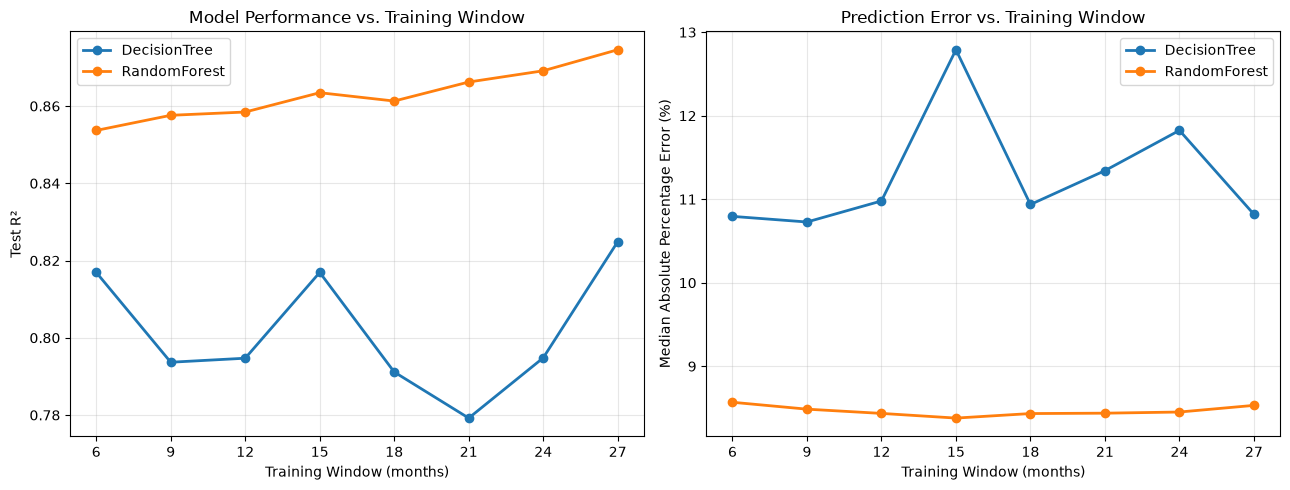

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in results.groupby("model"):

    group = group.sort_values("n_train_months")

    axes[0].plot(
        group["n_train_months"],
        group["test_R2"],
        marker="o",
        linewidth=2,
        label=name
    )

    axes[1].plot(
        group["n_train_months"],
        group["test_MdAPE_%"],
        marker="o",
        linewidth=2,
        label=name
    )

axes[0].set(
    xlabel="Training Window (months)",
    ylabel="Test R²",
    title="Model Performance vs. Training Window"
)

axes[1].set(
    xlabel="Training Window (months)",
    ylabel="Median Absolute Percentage Error (%)",
    title="Prediction Error vs. Training Window"
)

for ax in axes:
    ax.set_xticks(sorted(results["n_train_months"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

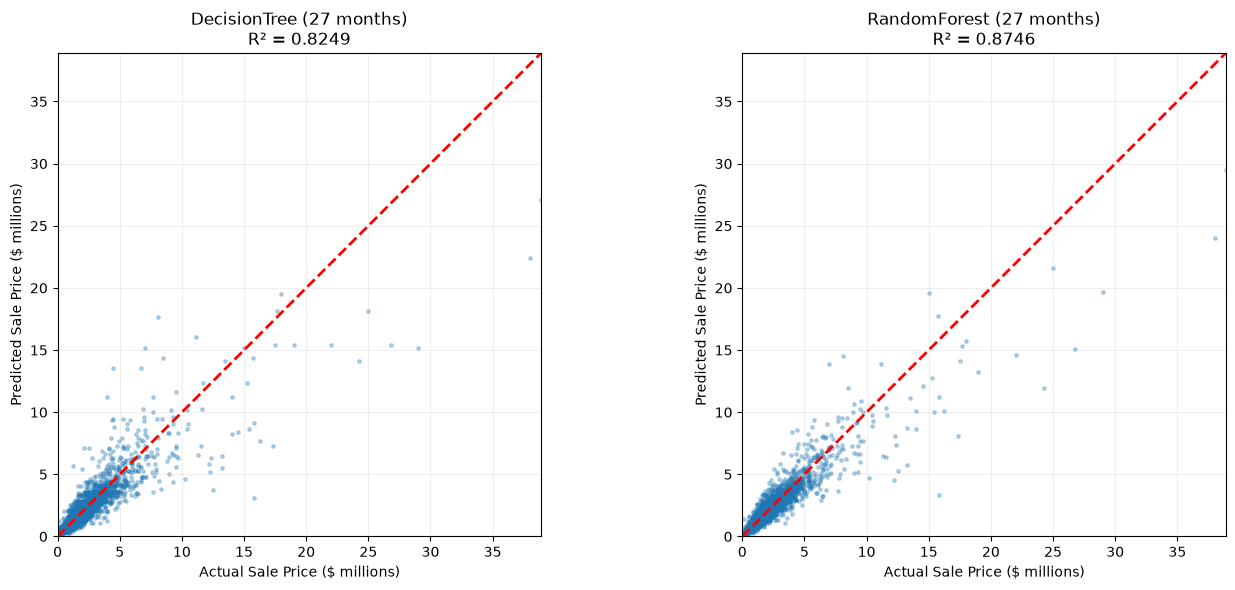

R2     MAPE_%    MdAPE_%          MAE_$  \
DecisionTree validation  0.789394  16.270420  10.673371  214924.881057   
             test        0.824871  16.118406  10.818951  217109.974326   
RandomForest validation  0.835672  13.191931   8.209579  179616.273101   
             test        0.874576  13.176321   8.531460  182178.238035   

                               MSE_$2         RMSE_$  
DecisionTree validation  4.218831e+11  649525.252172  
             test        3.477843e+11  589732.423203  
RandomForest validation  3.291800e+11  573742.103795  
             test        2.490765e+11  499075.660259

In [9]:
MONTHS = 27

folder = f"fe_outputs/train_{MONTHS}m"

X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)
models = best_models[MONTHS]  # use this window's validation-selected models

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models.items()):

    pred = model.predict(X_te)

    actual_millions = y_te / 1_000_000
    predicted_millions = pred / 1_000_000

    ax.scatter(
        actual_millions,
        predicted_millions,
        s=6,
        alpha=0.3
    )

    limit = max(
        actual_millions.max(),
        predicted_millions.max()
    )

    ax.plot(
        [0, limit],
        [0, limit],
        "r--",
        linewidth=2,
    )

    ax.set_xlabel("Actual Sale Price ($ millions)")
    ax.set_ylabel("Predicted Sale Price ($ millions)")

    ax.set_title(
        f"{name} ({MONTHS} months)\n"
        f"R² = {r2_score(y_te, pred):.4f}"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Validation vs. test metrics for the 24-month models
pd.concat({
    name: pd.DataFrame({
        "validation": metrics(y_val, model.predict(X_val)),
        "test": metrics(y_te, model.predict(X_te)),
    }).T
    for name, model in models.items()
})


## Feature importance

Importance scores from the 27-month models fit above. These are impurity-based importances: how much each feature reduces prediction error across the tree splits, scaled so they sum to 1. They show which features the model relies on most, but not the direction of the effect.

In [10]:
importances = pd.DataFrame({
    name: pd.Series(model.feature_importances_, index=X_tr.columns)
    for name, model in models.items()
}).sort_values("RandomForest", ascending=False)

importances.head(15)

,DecisionTree,RandomForest
est_value_area,0.095963,0.160393
log_est_value_area,0.438064,0.156528
PostalCode_cat_te,0.373584,0.074534
log_living_area,0.003932,0.061593
City_te,0.003468,0.057235
LivingArea,0.013821,0.053357
zip_med_ppsf_12m,0.000675,0.047481
area_ppsf_est,0.000043,0.045108
MLSAreaMajor_te,0.024600,0.039063
BathroomsTotalInteger,0.000210,0.038391


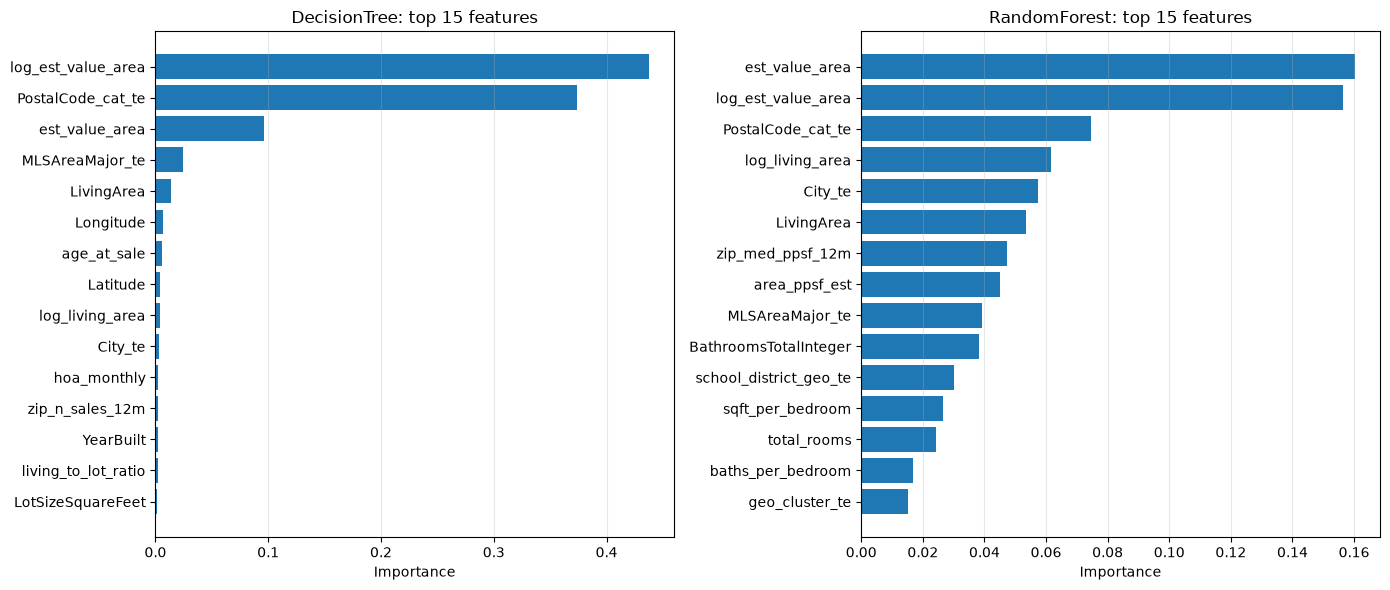

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name in zip(axes, importances.columns):
    top = importances[name].sort_values(ascending=False).head(15).iloc[::-1]
    ax.barh(top.index, top.values, color="tab:blue")
    ax.set(xlabel="Importance", title=f"{name}: top 15 features")
    ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()